# Step 4: Interpretable model, full-data EBM

66 named features plus an n-gram text score, trained by `experiments/11_full_convergence/ebm_full.py`. Details: `docs/steps/04_interpretable_ebm.md`.

In [1]:
# Imports and paths
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
import nbutils as U
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("model prediction groups found:", len(list(U.PRED_DIR.glob("*/sarc_random__test.parquet"))))

model prediction groups found: 22


In [2]:
# EBM vs reference models
M = ["ebm_full", "ebm_full_notext", "ebm_named340", "lr_word_char_surface", "lgbm_lrscore_cues_contrast", "lgbm_reply_tfidf_surface"]
test, val = U.predictions("sarc_random")
U.show(U.evaluate(test, val, M)[["label", "roc_auc", "precision", "recall", "f1", "p75_recall"]])

,label,roc_auc,precision,recall,f1,p75_recall
0,LightGBM + LR score + cues + contrast,0.8296,0.7746,0.7209,0.7468,0.7512
1,Full-data EBM (66 features + text score),0.8229,0.7712,0.7131,0.7410,0.7375
2,"LR, word + char n-grams",0.8184,0.7598,0.7226,0.7407,0.7290
3,"LightGBM, + surface (baseline)",0.8074,0.7559,0.7023,0.7281,0.7035
4,"Team EBM (200k rows, 340 features)",0.7620,0.7231,0.6416,0.6799,0.5798
5,"Full-data EBM, no text score",0.7123,0.7022,0.5558,0.6205,0.4615


In [3]:
# Paired bootstrap
U.show(pd.concat([U.bootstrap_vs(test, ["ebm_full"], ref="ebm_named340"),
                  U.bootstrap_vs(test, ["ebm_full"], ref="lr_word_char_surface"),
                  U.bootstrap_vs(test, ["ebm_full"], ref="lgbm_lrscore_cues_contrast")]))

,model,vs,d_auc,ci_low,ci_high
0,ebm_full,ebm_named340,0.0609,0.0590,0.0629
0,ebm_full,lr_word_char_surface,0.0045,0.0040,0.0050
0,ebm_full,lgbm_lrscore_cues_contrast,-0.0067,-0.0074,-0.0061


## 4.1 Training details

In [4]:
# Training details
j = U.read_json(U.EXP / "11_full_convergence/results/ebm_full__sarc_random.json")
print({k: j[k] for k in ["train_rows", "n_features", "n_terms", "fit_seconds", "val_auc"]})
print("boosting rounds per bag (all stopped early, i.e. converged):", j["best_rounds_per_bag"][:8])

{'train_rows': 639638, 'n_features': 66, 'n_terms': 81, 'fit_seconds': 270, 'val_auc': 0.8185431863430611}
boosting rounds per bag (all stopped early, i.e. converged): [64686, 92512, 51193, 53389, 63818, 33218, 55644, 52741]


## 4.2 Global term importance

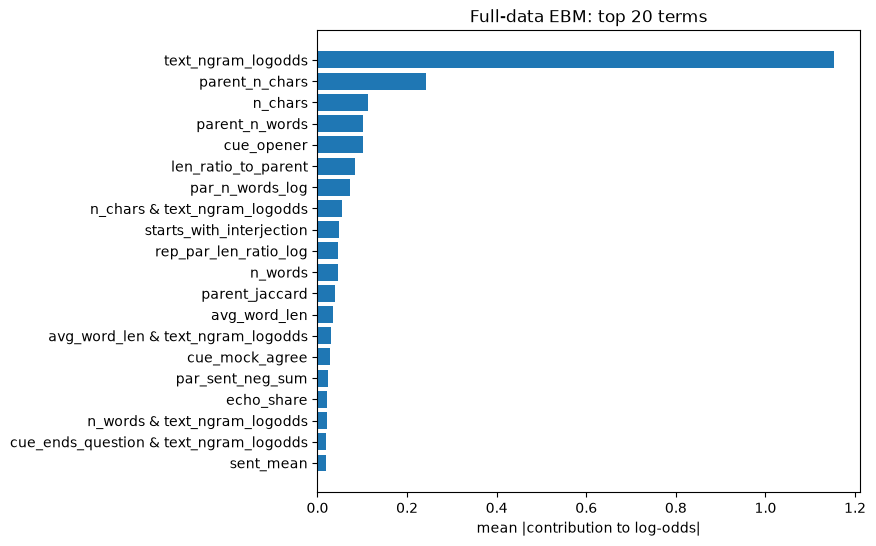

In [5]:
# Global term importance
imp = pd.read_csv(U.EXP / "11_full_convergence/results/ebm_full__sarc_random__term_importance.csv").head(20)
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(imp["term"][::-1], imp["importance"][::-1]); ax.set_xlabel("mean |contribution to log-odds|")
ax.set_title("Full-data EBM: top 20 terms"); U.savefig(fig, "S04_ebm_importance.png"); plt.show()

## 4.3 Explaining single predictions
Every prediction is exactly *intercept + sum of term contributions*; the text score splits further into individual n-gram weights.

In [6]:
# Single-prediction explanations
display(Markdown((U.EXP / "11_full_convergence/results/ebm_explanations.md").read_text(encoding="utf-8")))

# Full-data EBM: explanation examples (sarc_random)

## Global: EBM term importance (mean |contribution to log-odds|)

| Term | Importance |
|---|---:|
| text_ngram_logodds | 1.153 |
| parent_n_chars | 0.241 |
| n_chars | 0.113 |
| parent_n_words | 0.102 |
| cue_opener | 0.102 |
| len_ratio_to_parent | 0.084 |
| par_n_words_log | 0.073 |
| n_chars & text_ngram_logodds | 0.054 |
| starts_with_interjection | 0.049 |
| rep_par_len_ratio_log | 0.046 |
| n_words | 0.045 |
| parent_jaccard | 0.038 |
| avg_word_len | 0.034 |
| avg_word_len & text_ngram_logodds | 0.030 |
| cue_mock_agree | 0.029 |
| par_sent_neg_sum | 0.023 |
| echo_share | 0.022 |
| n_words & text_ngram_logodds | 0.021 |
| cue_ends_question & text_ngram_logodds | 0.020 |
| sent_mean | 0.020 |

## Largest n-gram weights inside the text score (LR coefficients)

Sarcastic direction: `w:yes because` +7.34, `c:'t '` +7.03, `w:but but` +5.58, `w:yeah because` +5.12, `c:'] '` +4.99, `w:good thing` +4.90, `c:'s '` +4.87, `w:not like` +4.45, `c:'What,'` +4.40, `w:how dare` +4.28, `w:but thought` +4.24, `w:or anything` +4.20, `w:would never` +4.16, `w:oh but` +4.14, `w:right because` +4.13, `w:everyone knows` +4.03, `c:'.] '` +3.95, `c:'.]'` +3.91, `c:'e '` +3.90, `c:' t'` +3.83

Non-sarcastic direction: `c:'. '` -10.50, `c:'! '` -9.64, `c:' ('` -6.37, `c:') '` -6.07, `c:' :'` -5.98, `w:not sure` -4.79, `c:'!"'` -4.72, `c:'!" '` -4.59, `w:pretty sure` -4.11, `w:make sure` -4.10, `c:'..'` -3.94, `c:' but '` -3.84, `w:doesn mean` -3.81, `w:for sure` -3.74, `w:the original` -3.62, `w:not really` -3.62, `c:'/ '` -3.56, `c:'( '` -3.53, `c:'- '` -3.50, `w:totally forgot` -3.41

## Example 1: Correct sarcastic (high confidence)

- Reply: `But that's not racism, that's the trufs!`
- Parent: `"They love to paint this sub as racist...just ignore the Nazi propaganda that is stickied to the frontpage!"`
- True label 1, EBM P(sarcastic) 0.946 (intercept +0.14)

| EBM term | Value | Contribution to log-odds |
|---|---|---:|
| text_ngram_logodds | 2.791 | +2.562 |
| n_exclam & par_exclam |  | -0.356 |
| cue_opener | 1.0 | +0.291 |
| parent_n_chars | 108.0 | +0.157 |
| len_ratio_to_parent | 0.368 | -0.088 |
| n_chars | 40.0 | +0.079 |
| parent_n_words | 19.0 | -0.071 |
| par_sent_neg_sum | -5.5 | +0.062 |

Text score +2.79 comes mainly from: `c:'! '` -0.62, `w:racism that` -0.35, `c:'t '` +0.33, `w:racism` +0.28, `c:'But '` +0.26, `c:' t'` +0.25, `c:'But'` +0.24, `w:that not` +0.24

## Example 2: Correct non-sarcastic (high confidence)

- Reply: `To be fair, missing the start of the college fall semester seems a pretty horrible mis-step, given that (a) college students seem to have an infinite amount of spare cash in September and (b) so many `
- Parent: `Announcing it now and not selling it by black friday or Christmas don't make much sense either. Nothing make sense atm. Maybe microsoft will do the unthinkable, host an event to anounce partners' new `
- True label 0, EBM P(sarcastic) 0.038 (intercept +0.14)

| EBM term | Value | Contribution to log-odds |
|---|---|---:|
| text_ngram_logodds | -2.723 | -2.450 |
| parent_n_chars | 218.0 | +0.361 |
| n_words | 43.0 | -0.302 |
| n_chars | 233.0 | -0.253 |
| n_chars & text_ngram_logodds |  | -0.175 |
| parent_n_words | 36.0 | -0.141 |
| par_n_words_log | 3.638 | -0.104 |
| n_words & text_ngram_logodds |  | -0.101 |

Text score -2.72 comes mainly from: `c:' ('` -0.41, `c:') '` -0.38, `w:many` -0.23, `c:'t '` +0.15, `w:amount` -0.15, `w:so many` +0.13, `w:college` -0.13, `c:'. '` -0.13

## Example 3: Error: non-sarcastic predicted as sarcastic

- Reply: `Maybe he's into pegging only, and is therefore a technical virgin.`
- Parent: `I think Haley Atwell has said that he isn't, which is... an interesting dynamic.`
- True label 0, EBM P(sarcastic) 0.919 (intercept +0.14)

| EBM term | Value | Contribution to log-odds |
|---|---|---:|
| text_ngram_logodds | 2.335 | +2.123 |
| parent_n_words | 14.0 | +0.065 |
| avg_word_len & text_ngram_logodds |  | +0.063 |
| cue_opener | 0.0 | -0.062 |
| par_n_words_log | 2.708 | +0.057 |
| n_words | 11.0 | +0.057 |
| n_chars & text_ngram_logodds |  | +0.053 |
| avg_word_len | 4.909 | +0.046 |

Text score +2.34 comes mainly from: `w:therefore` +0.54, `c:'. '` -0.23, `w:into` -0.22, `c:'s '` +0.15, `c:'eref'` +0.14, `c:'erefo'` +0.14, `c:' i'` +0.14, `w:maybe he` +0.13


## 4.4 Takeaways

- **Full-data EBM: 0.8229** on sarc_random test (0.8145 on sarc_subreddit), +0.061 over the team EBM and only ~0.007 below the best compliant LightGBM.
- The n-gram text score dominates (importance 1.15); without it the EBM drops to 0.712. Hand-made features add ≈ +0.0045 on top and make the explanation readable (openers, length, context).
- Strongest sarcastic n-grams are mock-agreement patterns (*yes because, yeah because, how dare, everyone knows*). Strongest non-sarcastic signals are replies ending with a full stop or exclamation mark — possibly an artefact of how SARC removed the `/s` marker (ablation A8 in the summary).
- No subreddit feature is used.